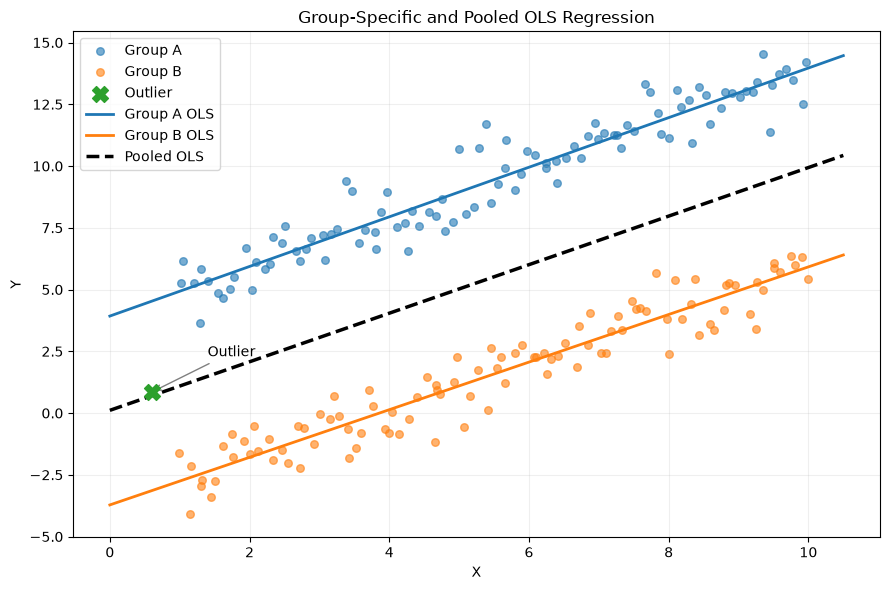

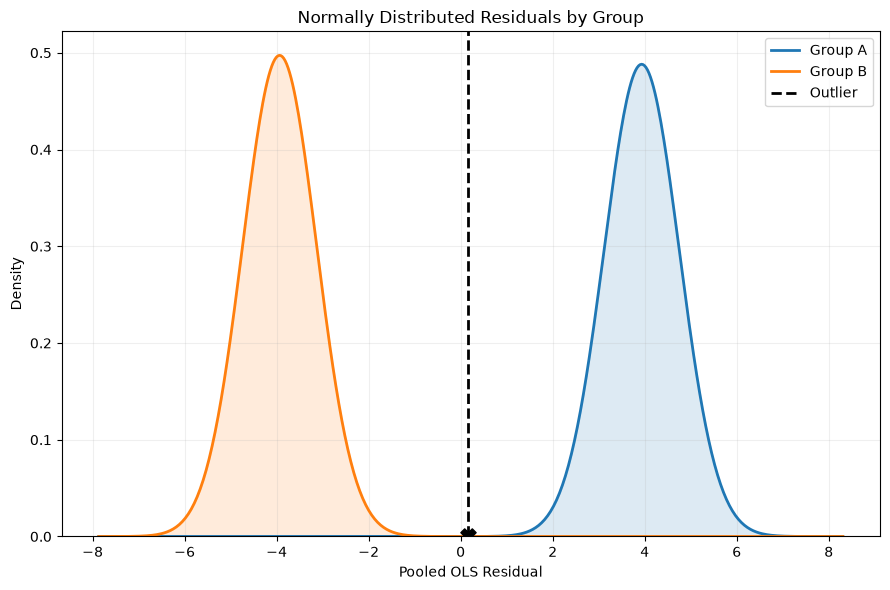

Group A:    y = 3.9271 + 1.0042x
Group B:    y = -3.7184 + 0.9637x
Pooled OLS: y = 0.1109 + 0.9829x

Residual distributions:
Group A: N(3.933, 0.817²)
Group B: N(-3.935, 0.802²)
Outlier residual: 0.149


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, norm

# --------------------------------------------------
# 1. Parameters
# --------------------------------------------------

rng = np.random.default_rng(42)

n = 100                 # Observations per group
separation = 8          # Distance between regression lines
sigma = 0.8             # Standard deviation of Gaussian noise
slope = 1.0

# --------------------------------------------------
# 2. Generate data
# --------------------------------------------------

# Same X distribution for both groups
x_a = np.linspace(1, 10, n) + rng.normal(0, 0.04, n)
x_b = np.linspace(1, 10, n) + rng.normal(0, 0.04, n)

# Normally distributed errors
eps_a = rng.normal(0, sigma, n)
eps_b = rng.normal(0, sigma, n)

# Group-specific intercepts
y_a = slope * x_a + separation / 2 + eps_a
y_b = slope * x_b - separation / 2 + eps_b

# Outlier near the origin, slightly biased toward Group A
x_out = 0.6
y_out = 0.85

df = pd.DataFrame({
    "x": np.concatenate([x_a, x_b, [x_out]]),
    "y": np.concatenate([y_a, y_b, [y_out]]),
    "group": (
        ["A"] * n +
        ["B"] * n +
        ["Outlier"]
    )
})

# --------------------------------------------------
# 3. Split groups
# --------------------------------------------------

a = df[df["group"] == "A"]
b = df[df["group"] == "B"]
o = df[df["group"] == "Outlier"]

# --------------------------------------------------
# 4. Fit OLS regression lines
# --------------------------------------------------

slope_a, intercept_a = np.polyfit(a["x"], a["y"], 1)
slope_b, intercept_b = np.polyfit(b["x"], b["y"], 1)

# Pooled OLS includes the outlier
slope_pool, intercept_pool = np.polyfit(df["x"], df["y"], 1)

x_line = np.linspace(0, 10.5, 200)

# --------------------------------------------------
# 5. Regression plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    a["x"], a["y"],
    color="tab:blue",
    alpha=0.6,
    s=30,
    label="Group A"
)

ax.scatter(
    b["x"], b["y"],
    color="tab:orange",
    alpha=0.6,
    s=30,
    label="Group B"
)

ax.scatter(
    o["x"], o["y"],
    color="tab:green",
    marker="X",
    s=130,
    label="Outlier",
    zorder=5
)

ax.plot(
    x_line,
    intercept_a + slope_a * x_line,
    color="tab:blue",
    linewidth=2,
    label="Group A OLS"
)

ax.plot(
    x_line,
    intercept_b + slope_b * x_line,
    color="tab:orange",
    linewidth=2,
    label="Group B OLS"
)

ax.plot(
    x_line,
    intercept_pool + slope_pool * x_line,
    color="black",
    linestyle="--",
    linewidth=2.5,
    label="Pooled OLS"
)

ax.annotate(
    "Outlier",
    xy=(x_out, y_out),
    xytext=(1.4, 2.3),
    arrowprops=dict(arrowstyle="->", color="gray")
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Group-Specific and Pooled OLS Regression")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Calculate pooled OLS residuals
# --------------------------------------------------

df["residual"] = (
    df["y"] -
    (intercept_pool + slope_pool * df["x"])
)

resid_a = df.loc[df["group"] == "A", "residual"].values
resid_b = df.loc[df["group"] == "B", "residual"].values

outlier_resid = df.loc[
    df["group"] == "Outlier", "residual"
].iloc[0]

# --------------------------------------------------
# 7. Estimate residual densities
# --------------------------------------------------

grid = np.linspace(
    df["residual"].min() - 2,
    df["residual"].max() + 2,
    500
)

# Fit normal distributions to residuals
mu_a, sd_a = norm.fit(resid_a)
mu_b, sd_b = norm.fit(resid_b)

density_a = norm.pdf(grid, mu_a, sd_a)
density_b = norm.pdf(grid, mu_b, sd_b)

# --------------------------------------------------
# 8. Plot residual densities
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    grid, density_a,
    color="tab:blue",
    linewidth=2,
    label="Group A"
)

ax.fill_between(
    grid, density_a,
    color="tab:blue",
    alpha=0.15
)

ax.plot(
    grid, density_b,
    color="tab:orange",
    linewidth=2,
    label="Group B"
)

ax.fill_between(
    grid, density_b,
    color="tab:orange",
    alpha=0.15
)

# Outlier
ax.axvline(
    outlier_resid,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Outlier"
)

ax.scatter(
    outlier_resid,
    0,
    color="black",
    marker="X",
    s=120,
    zorder=5
)

ax.set_xlabel("Pooled OLS Residual")
ax.set_ylabel("Density")
ax.set_title("Normally Distributed Residuals by Group")

ax.legend()
ax.grid(alpha=0.2)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 9. Print results
# --------------------------------------------------

print(f"Group A:    y = {intercept_a:.4f} + {slope_a:.4f}x")
print(f"Group B:    y = {intercept_b:.4f} + {slope_b:.4f}x")
print(f"Pooled OLS: y = {intercept_pool:.4f} + {slope_pool:.4f}x")

print("\nResidual distributions:")
print(f"Group A: N({mu_a:.3f}, {sd_a:.3f}²)")
print(f"Group B: N({mu_b:.3f}, {sd_b:.3f}²)")
print(f"Outlier residual: {outlier_resid:.3f}")